Dataset: Breast Cancer Wisconsin
Total samples: 569
Total features: 30

Target classes:
['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980    

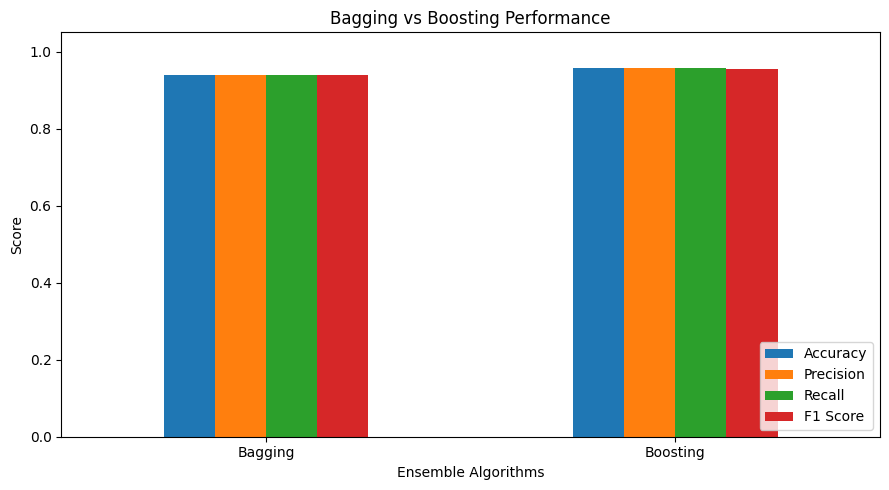

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset: Breast Cancer Wisconsin")
print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])

print("\nTarget classes:")
print(data.target_names)

print("\nFirst five rows:")
print(X.head())


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

bagging_predictions = bagging_model.predict(X_test)


boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

boosting_model.fit(X_train, y_train)

boosting_predictions = boosting_model.predict(X_test)


def evaluate_model(name, y_test, predictions):

    print("\n================================")
    print(name)
    print("================================")

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average='weighted'
    )
    recall = recall_score(
        y_test, predictions, average='weighted'
    )
    f1 = f1_score(
        y_test, predictions, average='weighted'
    )

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    ))

    return accuracy, precision, recall, f1


bagging_results = evaluate_model(
    "BAGGING CLASSIFIER",
    y_test,
    bagging_predictions
)

boosting_results = evaluate_model(
    "BOOSTING CLASSIFIER",
    y_test,
    boosting_predictions
)


results = pd.DataFrame(
    [bagging_results, boosting_results],
    columns=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    index=['Bagging', 'Boosting']
)

print("\n========== MODEL COMPARISON ==========")
print(results)


results.plot(kind='bar', figsize=(9, 5))

plt.title("Bagging vs Boosting Performance")
plt.ylabel("Score")
plt.xlabel("Ensemble Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
